# Replicating our paper's CIFAR-10 experiment: the starter

Our paper (Wang, Belkin and Wang, 2026, [arXiv 2602.11395](https://arxiv.org/abs/2602.11395)) steers a pretrained
diffusion model toward a class without retraining it, in two stages:
- **noise alignment (NA)** in the early, high-noise steps: the CFG recipe with two Gaussian denoisers;
- **RFM steering** in the later steps: edit the features of one block of the network along a class direction
  $v_{\mathrm{RFM}}$, then apply the CFG recipe again.

Table 2 of the paper measures both on CIFAR-10. This notebook installs the paper's code and runs every step once,
for one class: cars (CIFAR-10's "automobile", class 1), the running example from the Nov 4 slides. The replication
itself, with all ten classes and five rows of Table 2, is yours; section 5 lists it.

## Coding assignment, due Friday, November 13

First, finish your checkpoint, due this Friday, November 6. Then run this notebook on a GPU (DSMLP or Colab) and
do the replication in section 5: a table next to the paper's Table 2, sample grids, and a paragraph on what matches
and what does not. `Nov_4_assignment.pdf` has the rest of the assignment, for this week and next, and what to
submit.

**Notation, as on the slides:** $x_1$ is a clean image, $x_0$ is noise and $\sigma$ the noise level, so a noisy
image is $x = x_1 + \sigma x_0$. The paper writes the clean image as $x_0$ and the noise as $\epsilon$. Its model
works with $x_t = \sqrt{\bar\alpha_t}\, x_1 + \sqrt{1-\bar\alpha_t}\, x_0$; dividing by $\sqrt{\bar\alpha_t}$ gives
$x = x_1 + \sigma x_0$ with $\sigma = \sqrt{(1-\bar\alpha_t)/\bar\alpha_t}$, the $\sigma$ in the paper's
Appendix H.

## 0. Setup

The setup downloads:
- the paper's code, [na-rfm](https://github.com/isotrivial/na-rfm), with the
  [TFG code](https://github.com/YWolfeee/Training-Free-Guidance) it builds on, each at a fixed version;
- the CIFAR-10 diffusion model the paper uses, the U-Net of OpenAI's improved DDPM (210 MB);
- CIFAR-10, from Hugging Face (140 MB).

`run` prints a command, runs it in the code's folder, and stops the notebook if it fails.

Two lines need a fix for current library versions, and the cell makes both:
- The paper's FID script loads CIFAR-10 from Hugging Face under the dataset's old name, `cifar10`, which current
  versions of the `datasets` library reject. The fix uses the current name, `uoft-cs/cifar10`.
- TFG's FID code imports a private part of SciPy that, in SciPy 1.16, fails unless another part loads first. The
  fix adds that import.

In [ ]:
import hashlib, json, os, subprocess, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none: switch to a GPU runtime")
HOME = Path("/content") if Path("/content").exists() else Path.cwd()   # Colab, or the folder you start in
REPO = HOME / "na-rfm"
TFG = REPO / "baselines" / "tfg"
NARFM_COMMIT = "8e9619bc6735b03d73056bfdc13dd3659b96e127"   # the paper's public code, Oct 27, 2026
TFG_COMMIT = "f8d17f3ec2f0e7377dedf7b7bc62fad15f36cb77"     # Training-Free-Guidance, Oct 29, 2025


def run(cmd, cwd=None):
    print("$", cmd, flush=True)
    t0 = time.time()
    proc = subprocess.run(cmd, shell=True, cwd=cwd or REPO, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    lines = [line for line in proc.stdout.splitlines() if "it/s]" not in line and "s/it]" not in line]   # no progress bars
    print("\n".join(lines[-25:]))
    if proc.returncode != 0:
        raise RuntimeError(f"failed with exit code {proc.returncode}: {cmd}")
    print(f"[{time.time() - t0:.0f} s]")


def fix(path, old, new):
    text = path.read_text()
    if new not in text:
        path.write_text(text.replace(old, new))


if not REPO.exists():
    run(f"git clone -q https://github.com/isotrivial/na-rfm.git {REPO}", cwd=HOME)
run(f"git checkout -q {NARFM_COMMIT}")
if not TFG.exists():
    run(f"git clone -q https://github.com/YWolfeee/Training-Free-Guidance.git {TFG}")
run(f"git checkout -q {TFG_COMMIT}", cwd=TFG)
run(f"{sys.executable} -m pip install -q datasets scikit-learn scipy transformers gdown")

fix(REPO / "repro" / "evaluate_saved_samples.py", 'load_dataset("cifar10")', 'load_dataset("uoft-cs/cifar10")')
sqrtm_import = "from scipy.linalg._matfuncs_sqrtm_triu import within_block_loop"
fix(TFG / "evaluations" / "utils" / "torch_sqrtm.py", sqrtm_import, "import scipy.linalg._matfuncs_sqrtm\n" + sqrtm_import)

os.chdir(REPO)
os.environ["PYTHONPATH"] = f"{REPO}:{TFG}"   # for the scripts this notebook runs
sys.path[:0] = [str(REPO), str(TFG)]         # for this notebook itself

GPU: Tesla T4
$ git clone -q https://github.com/isotrivial/na-rfm.git /content/na-rfm

[1 s]
$ git checkout -q 8e9619bc6735b03d73056bfdc13dd3659b96e127

[0 s]
$ git clone -q https://github.com/YWolfeee/Training-Free-Guidance.git /content/na-rfm/baselines/tfg

[1 s]
$ git checkout -q f8d17f3ec2f0e7377dedf7b7bc62fad15f36cb77

[0 s]
$ /usr/bin/python3 -m pip install -q datasets scikit-learn scipy transformers gdown

[2 s]


The model: na-rfm loads the checkpoint file that TFG distributes, `openai_cifar10.pt`, from TFG's shared
folder. The check below makes sure you have exactly the file the paper used. If `gdown` fails (Google Drive limits
popular files), download `openai_cifar10.pt` by hand from
[TFG's folder](https://drive.google.com/drive/folders/1fS7dKpO4O-FjaLwuRXuHBxEOlkqMMTGh) into
`na-rfm/data/checkpoints/` and run the cell again.

In [ ]:
CKPT = REPO / "data" / "checkpoints" / "openai_cifar10.pt"
if not CKPT.exists():
    CKPT.parent.mkdir(parents=True, exist_ok=True)
    run(f"gdown 1eInndCjx389Tl45kfmntVo23f_-82bHl -O {CKPT}")
md5 = hashlib.md5(CKPT.read_bytes()).hexdigest()
assert md5 == "2754c3e3c778ef6e0ab98e8aacaefaf9", f"not the paper's checkpoint (md5 {md5}): delete it and download again"
print(f"checkpoint OK: {CKPT.stat().st_size / 1e6:.0f} MB")

$ gdown 1eInndCjx389Tl45kfmntVo23f_-82bHl -O /content/na-rfm/data/checkpoints/openai_cifar10.pt
Downloading...
From (original): https://drive.google.com/uc?id=1eInndCjx389Tl45kfmntVo23f_-82bHl
From (redirected): https://drive.google.com/uc?id=1eInndCjx389Tl45kfmntVo23f_-82bHl&confirm=t&uuid=bb7e254a-a9f4-41cc-b7a6-0c531b6861bc
To: /content/na-rfm/data/checkpoints/openai_cifar10.pt

  0%|          | 0.00/210M [00:00<?, ?B/s]
  1%|          | 2.62M/210M [00:00<00:08, 24.5MB/s]
  7%|▋         | 14.2M/210M [00:00<00:02, 75.9MB/s]
 11%|█         | 22.5M/210M [00:00<00:02, 79.3MB/s]
 16%|█▌        | 33.0M/210M [00:00<00:02, 86.5MB/s]
 20%|██        | 43.0M/210M [00:00<00:01, 89.7MB/s]
 26%|██▌       | 54.0M/210M [00:00<00:01, 95.7MB/s]
 33%|███▎      | 68.7M/210M [00:00<00:01, 112MB/s] 
 38%|███▊      | 80.2M/210M [00:00<00:01, 93.5MB/s]
 44%|████▍     | 93.3M/210M [00:00<00:01, 103MB/s] 
 50%|████▉     | 104M/210M [00:01<00:01, 101MB/s] 
 56%|█████▌    | 117M/210M [00:01<00:00, 106MB/s]
 62

CIFAR-10's 50,000 training images, one folder per class (`label_0` to `label_9`), which is the layout the
paper's PCA script reads. Class 1 is the cars.

In [ ]:
from datasets import load_dataset
from PIL import Image

CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
CAR = 1
BY_CLASS = HOME / "cifar10" / "train_by_class"
cifar = load_dataset("uoft-cs/cifar10", split="train")
assert cifar.features["label"].names == CLASSES
labels = np.array(cifar["label"])
pixels = np.stack([np.asarray(img) for img in cifar["img"]])   # 50,000 x 32 x 32 x 3, values 0 to 255
if not (BY_CLASS / "label_9").exists():
    for i, (img, y) in enumerate(zip(pixels, labels)):
        folder = BY_CLASS / f"label_{y}"
        folder.mkdir(parents=True, exist_ok=True)
        Image.fromarray(img).save(folder / f"{i:05d}.png")
print({CLASSES[k]: len(list((BY_CLASS / f"label_{k}").glob("*.png"))) for k in range(10)})

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

{'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}


## 1. Noise alignment's two Gaussian denoisers

Noise alignment needs two Gaussian denoisers, one from the 5,000 training cars ($D_{\mathrm{car}}$) and one from all
50,000 training images ($D_{\mathrm{all}}$). Each keeps a mean image $\mu$ and the top $k = 1{,}000$ PCA directions
$u_k$ with their variances $\nu_k$ (the paper's Table 16), and denoises with the formula from the slides:

$$D(x;\sigma) = \mu + \sum_k \frac{\nu_k}{\nu_k + \sigma^2}\, \langle x - \mu,\, u_k\rangle\, u_k .$$

`pca/build_filters.py` computes $\mu$, $u_k$ and $\nu_k$, and saves them as `class_1.pt` and `full_dataset.pt`.

$D_{\mathrm{all}}$ must see every class, so it is built with `--num-images 0`, which means all 50,000 images. With
`--full-dataset`, the script keeps the first N files in folder order, so N = 5,000 would be airplanes only.

This cell takes a few minutes, mostly for the PCA of all 50,000 images.

In [ ]:
FILTERS = REPO / "repro" / "assets" / "cifar10_filters"
build = (f"{sys.executable} pca/build_filters.py --image-root {BY_CLASS} --output-dir {FILTERS} "
         f"--image-size 32 --components 1000 --backend cpu")
if not (FILTERS / "full_dataset.pt").exists():
    run(f"{build} --full-dataset --num-images 0")          # D_all: all 50,000 training images
if not (FILTERS / f"class_{CAR}.pt").exists():
    run(f"{build} --classes {CAR} --num-images 5000")      # D_car: the 5,000 training cars

$ /usr/bin/python3 pca/build_filters.py --image-root /content/cifar10/train_by_class --output-dir /content/na-rfm/repro/assets/cifar10_filters --image-size 32 --components 1000 --backend cpu --full-dataset --num-images 0
Using PCA backend: cpu

[415 s]
$ /usr/bin/python3 pca/build_filters.py --image-root /content/cifar10/train_by_class --output-dir /content/na-rfm/repro/assets/cifar10_filters --image-size 32 --components 1000 --backend cpu --classes 1 --num-images 5000
Using PCA backend: cpu

[37 s]


What the two Gaussian denoisers keep: the mean image and the first PCA directions, for cars and for all
images. Grey is zero; a direction is added to or subtracted from the mean.

cars: 5000 images, 1000 directions
all images: 50000 images, 1000 directions


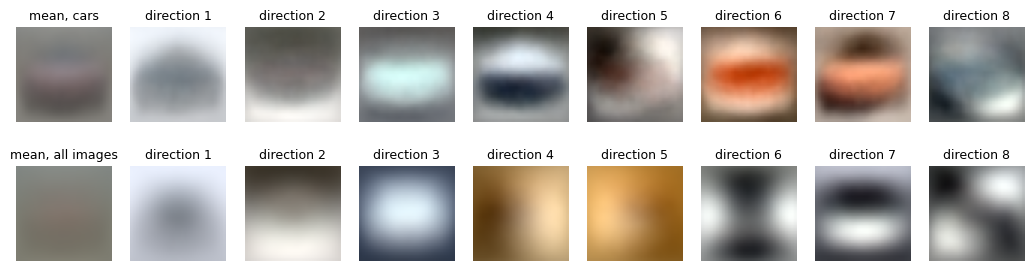

In [ ]:
def as_image(v):
    return np.clip(v.reshape(3, 32, 32).transpose(1, 2, 0) / 2 + 0.5, 0, 1)   # [-1, 1] -> [0, 1]


def as_direction(u):
    u = u.reshape(3, 32, 32).transpose(1, 2, 0)
    return np.clip(0.5 + 0.5 * u / np.abs(u).max(), 0, 1)


fig, axes = plt.subplots(2, 9, figsize=(13, 3.3))
for row, (name, file) in enumerate([("cars", f"class_{CAR}.pt"), ("all images", "full_dataset.pt")]):
    f = torch.load(FILTERS / file, weights_only=False)
    axes[row, 0].imshow(as_image(f["mean_patch"].numpy()))
    axes[row, 0].set_title(f"mean, {name}", fontsize=9)
    for k in range(8):
        axes[row, k + 1].imshow(as_direction(f["eigenvectors"][:, k].numpy()))
        axes[row, k + 1].set_title(f"direction {k + 1}", fontsize=9)
    print(f"{name}: {f['num_images']} images, {f['eigenvectors'].shape[1]} directions")
for ax in axes.flat:
    ax.axis("off")
plt.show()

## 2. The RFM direction for cars

RFM steering edits the features $h$ of one block of the network: input block 9, with 256 numbers at each of
8 × 8 positions, 16,384 in all. To find the car direction $v_{\mathrm{RFM}}$, the paper (Table 16):
1. takes 1,000 training images of each class and adds a little noise, $\sigma \approx 0.21$, which is the model's
   step $t = 60$;
2. records $h$ for each image;
3. fits an RFM classifier, cars against the other nine classes, with a Laplace kernel, bandwidth 100,
   regularization $10^{-3}$ and 5 iterations;
4. combines the top three eigenvectors of what RFM learned into $v_{\mathrm{RFM}}$.

The classifier is checked on 20% of the images it did not see; AUC is the probability that it scores a random car
above a random non-car.

In [ ]:
from torch.utils.data import DataLoader, TensorDataset

from na_rfm.activation_collection import collect_activations
from na_rfm.model_loaders import load_openai_unet
from na_rfm.rfm_training import RFMTrainConfig, get_direction, train_binary_rfm

SIGMA = 0.21
first = np.concatenate([np.flatnonzero(labels == k)[:1000] for k in range(10)])   # the first 1,000 of each class
images = torch.from_numpy(pixels[first]).permute(0, 3, 1, 2).float() / 127.5 - 1   # in [-1, 1]
loader = DataLoader(TensorDataset(images, torch.from_numpy(labels[first])), batch_size=250)

unet = load_openai_unet(str(CKPT), image_size=32, device="cuda")
torch.manual_seed(0)
H, H_labels = collect_activations(unet, loader, block_name="input_blocks_9",
                                  alpha_prod_t=1 / (1 + SIGMA**2), timestep=60, device="cuda")
print("features h:", tuple(H.shape))
del unet
torch.cuda.empty_cache()

features h: (10000, 16384)


In [ ]:
CONCEPTS = REPO / "repro" / "assets" / "cifar10_concepts"
CONCEPTS.mkdir(parents=True, exist_ok=True)

t0 = time.time()
config = RFMTrainConfig(bandwidth=100.0, reg=1e-3, n_iters=5, top_k=3, device="cuda")
result = train_binary_rfm(H, H_labels, target_value=CAR, config=config)
v_rfm = get_direction(result, topk=3).cpu()
torch.save({"direction": v_rfm, "eigenvectors": result.eigenvectors.cpu(), "eigenvalues": result.eigenvalues.cpu(),
            "sign": int(result.sign), "auc": float(result.best_auc), "block_name": "input_blocks_9",
            "timestep": 60, "sigma": SIGMA}, CONCEPTS / f"class_{CAR}.pt")
print(f"cars against the rest: AUC {result.best_auc:.3f} on held-out images ({time.time() - t0:.0f} s)")

cars against the rest: AUC 0.969 on held-out images (50 s)


## 3. The paper's smoke test

`cifar10.sh` is the paper's launcher. With `MODE=smoke` it draws 4 images of one class twice: with noise
alignment only ($\lambda = 8$), and with NA-RFM. It measures accuracy with the paper's evaluator, a ConvNeXt-Tiny
classifier fine-tuned on CIFAR-10. If this cell passes, your setup works.

$ MODE=smoke TARGETS=1 bash cifar10.sh
cifar10_camera_ready_start=2026-11-13T03:51:19+0000
mode=smoke output_dir=results/camera_ready_repro targets=1
num_samples=4 seed_start=0 batch_size=64
Wrapper manifest written to: results/camera_ready_repro/_wrapper_runs/20261113_035119_159875
[1/1] running cifar10/na_only/class_1
  log: results/camera_ready_repro/_wrapper_runs/20261113_035119_159875/logs/001_cifar10_na_only_class_1.log
Completed. Wrapper logs are in: results/camera_ready_repro/_wrapper_runs/20261113_035119_159875
Wrapper manifest written to: results/camera_ready_repro/_wrapper_runs/20261113_035147_084980
[1/1] running cifar10/na_rfm/1
  log: results/camera_ready_repro/_wrapper_runs/20261113_035147_084980/logs/001_cifar10_na_rfm_1.log
Completed. Wrapper logs are in: results/camera_ready_repro/_wrapper_runs/20261113_035147_084980
cifar10_camera_ready_done=2026-11-13T03:52:04+0000
[46 s]


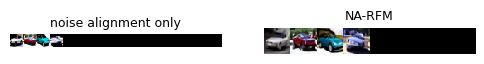

In [ ]:
run(f"MODE=smoke TARGETS={CAR} bash cifar10.sh")

smoke = REPO / "results" / "camera_ready_repro" / "cifar10"
fig, axes = plt.subplots(1, 2, figsize=(6, 1.8))
for ax, (name, path) in zip(axes, [("noise alignment only", next((smoke / "na_only").glob("automobile_*.png"))),
                                   ("NA-RFM", smoke / "na_rfm" / "automobile" / "grid.png")]):
    ax.imshow(Image.open(path), interpolation="nearest")
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.show()

## 4. A first measurement: 64 cars, unguided and with NA-RFM

Both rows start from the same 64 noises (seeds 0 to 63) and differ only in the steering:
- **unguided:** $\lambda = 0$ and $w_{\mathrm{RFM}} = 0$, so nothing is steered;
- **NA-RFM:** the paper's setting, which is the script's default: $\lambda = 3$ while $\sigma \ge 3.33$, then the
  edit $h \leftarrow h + w_{\mathrm{RFM}}\,\|h\|\,v_{\mathrm{RFM}}$ with $w_{\mathrm{RFM}} = 1$ and amplification
  $s = 2$ while $\sigma \in [0.01, 11.69]$.

Two numbers for each row:
- **accuracy:** the percentage of images the evaluator calls a car;
- **FID:** against all 6,000 CIFAR-10 cars, train and test.

With only 64 images FID is far higher than the paper's, because FID is biased upward when there are few
images. Compare rows only at the same number of images.

$ /usr/bin/python3 repro/run_cifar10_na_rfm.py --classes 1 --num-samples 64 --batch-size 64 --output-dir /content/na-rfm/results/first/unguided --gaussian-strength 0 --rfm-strength 0
Loading CIFAR-10 diffusion model: data/checkpoints/openai_cifar10.pt

Sampling 1 (automobile)

automobile: 6/64 = 9.4%

Average accuracy: 9.4%
Results saved to: /content/na-rfm/results/first/unguided
[45 s]
$ /usr/bin/python3 repro/evaluate_saved_samples.py --dataset cifar10 --samples-root /content/na-rfm/results/first/unguided --targets 1 --output /content/na-rfm/results/first/unguided/quality.json --batch-size 64
 51%|█████▏    | 46.8M/91.2M [00:00<00:00, 67.3MB/s]
 61%|██████    | 55.4M/91.2M [00:00<00:00, 74.0MB/s]
 69%|██████▉   | 62.8M/91.2M [00:01<00:00, 69.1MB/s]
 77%|███████▋  | 70.1M/91.2M [00:01<00:00, 63.3MB/s]
 85%|████████▌ | 77.8M/91.2M [00:01<00:00, 67.1MB/s]
 93%|█████████▎| 84.4M/91.2M [00:01<00:00, 57.9MB/s]
 99%|█████████▉| 90.2M/91.2M [00:01<00:00, 58.2MB/s]
100%|██████████| 91.2M/91.2

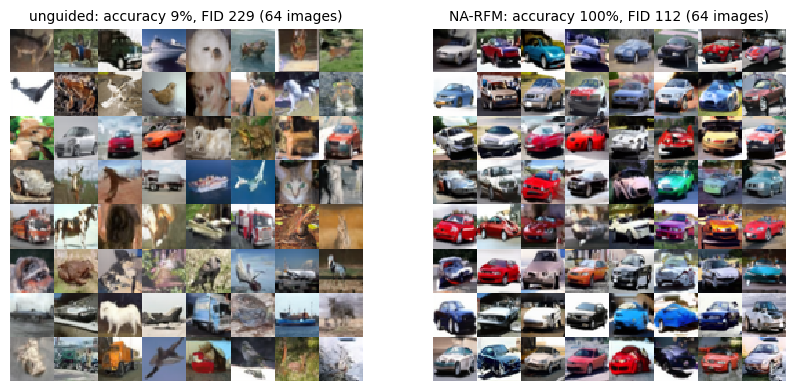

In [ ]:
FIRST = REPO / "results" / "first"
ROWS = {"unguided": "--gaussian-strength 0 --rfm-strength 0", "NA-RFM": ""}
scores = {}
for name, flags in ROWS.items():
    out = FIRST / name
    run(f"{sys.executable} repro/run_cifar10_na_rfm.py --classes {CAR} --num-samples 64 --batch-size 64 "
        f"--output-dir {out} {flags}")
    run(f"{sys.executable} repro/evaluate_saved_samples.py --dataset cifar10 --samples-root {out} --targets {CAR} "
        f"--output {out / 'quality.json'} --batch-size 64")
    scores[name] = json.loads((out / "quality.json").read_text())

fig, axes = plt.subplots(1, 2, figsize=(10, 5.5))
for ax, name in zip(axes, ROWS):
    q = scores[name]
    ax.imshow(Image.open(FIRST / name / "automobile" / "grid.png"), interpolation="nearest")
    ax.set_title(f"{name}: accuracy {q['average_accuracy']:.0f}%, FID {q['average_fid']:.0f} (64 images)", fontsize=10)
    ax.axis("off")
plt.show()

Table 2 also reports sampling time, for a batch of 16 images with 100 DDIM steps on an A100. We time the
batch size the scripts use, 64. `seconds_per_image` draws two batches of 64 cars after a warm-up batch and returns
the seconds per image. Pass it the same flags as the row's script.

In [ ]:
from na_rfm.ddim_sampling import build_ddim_schedule
from repro import run_cifar10_na_only as na_only
from repro.run_cifar10_na_rfm import parse_args, sample_class

unet = load_openai_unet(str(CKPT), image_size=32, device="cuda")


def seconds_per_image(flags="", na_only_strength=None, batch=64, repeats=2):
    # flags: those of run_cifar10_na_rfm.py; or na_only_strength=lambda, for run_cifar10_na_only.py --mode diff
    if na_only_strength is None:
        args = parse_args(f"--classes {CAR} --num-samples {batch} --batch-size {batch} {flags}".split())
        schedule = build_ddim_schedule(1000, args.inference_steps, 0.0001, 0.02, "cuda")
        draw = lambda: sample_class(unet=unet, schedule=schedule, class_idx=CAR, args=args)
    else:
        schedule = na_only.build_ddim_schedule(1000, 100, 0.0001, 0.02, "cuda")
        guidance = na_only.WienerGuidance(str(FILTERS / f"class_{CAR}.pt"), str(FILTERS / "full_dataset.pt"),
                                          mode="diff", strength=na_only_strength, start_step=0, end_step=50,
                                          num_components=1000, device="cuda")
        draw = lambda: na_only.sample_with_wiener_guidance(unet, schedule, guidance, batch,
                                                           na_only.StackedRandomGenerator("cuda", list(range(batch))))
    times = []
    for _ in range(repeats + 1):   # the first batch warms up the GPU
        torch.cuda.synchronize()
        t0 = time.time()
        with torch.no_grad():
            draw()
        torch.cuda.synchronize()
        times.append(time.time() - t0)
    return min(times[1:]) / batch


print(f"NA-RFM: {seconds_per_image():.2f} s per image at batch size 64 on {torch.cuda.get_device_name(0)}")
print("(the paper's Table 2: 6.2 s for a batch of 16 on an A100)")

NA-RFM: 0.54 s per image at batch size 64 on Tesla T4
(the paper's Table 2: 6.2 s for a batch of 16 on an A100)


## 5. Your turn: the replication (due Friday, November 13)

**a. The offline parts for all ten classes.**
- Build `class_k.pt` for every class: section 1's command with `--classes 0 2 3 4 5 6 7 8 9`.
- Fit an RFM direction for every class: section 2's last cell with `target_value=k`, saved as `class_k.pt`.
  Report each class's AUC.

**b. Five rows, 256 images per class**, with seeds 0 to 255 in every row and 100 DDIM steps. All settings are
in the paper's Tables 16 and 17:

| Row | Script | Noise alignment | RFM steering |
|---|---|---|---|
| Unguided (not in Table 2) | `run_cifar10_na_rfm.py` | none, $\lambda = 0$ | none, $w_{\mathrm{RFM}} = 0$ |
| Noise alignment only, $\lambda = 3$ | `run_cifar10_na_only.py --mode diff` | $\lambda = 3$ while $\sigma \ge 3.33$ (steps 0 to 50) | none |
| Noise alignment only, $\lambda = 8$ | `run_cifar10_na_only.py --mode diff` | $\lambda = 8$ while $\sigma \ge 3.33$ (steps 0 to 50) | none |
| RFM only (all steps) | `run_cifar10_na_rfm.py` | none, $\lambda = 0$ | $w_{\mathrm{RFM}} = 1$, $s = 2$, at every step |
| NA-RFM | `run_cifar10_na_rfm.py` | $\lambda = 3$ while $\sigma \ge 3.33$ | $w_{\mathrm{RFM}} = 1$, $s = 2$, while $\sigma \in [0.01, 11.69]$ |

Each script's `--help` lists its flags.
- In `run_cifar10_na_rfm.py`, `--gaussian-strength` is $\lambda$, `--rfm-strength` is $w_{\mathrm{RFM}}$,
  `--cfg-scale` is $s$, and `--rfm-sigma-lo` and `--rfm-sigma-hi` set the RFM window. "Every step" means a window
  wider than every $\sigma$ the sampler visits; the largest is about 157.
- In `run_cifar10_na_only.py`, `--strength` is $\lambda$, `--num-seeds` is the number of images, and
  `--start-step 0 --end-step 50` is its window. Add `--eval-mode hf_convnext` so that it uses the paper's evaluator.

**c. Measure each row.**
- **Accuracy:** from the ConvNeXt evaluator, averaged over the ten classes.
- **FID:** for each class, against that class's 6,000 CIFAR-10 images with `repro/evaluate_saved_samples.py`,
  then averaged over the ten classes, as in the paper.
- **Time:** seconds per image at batch size 64, with `seconds_per_image` above. Table 2 timed a batch of 16 on an
  A100, so compare your settings with each other rather than your seconds with the paper's.

**d. Show.**
- A table like Table 2, with your numbers next to the paper's.
- For each row, the first 16 images of every class, like the paper's Figures 9 and 10.
- A paragraph on what matches the paper, what does not, and why.

**Encouraged:**
- NA-RFM at the paper's 2,048 images per class, to compare FID with Table 2 directly.
- A noise-alignment-only sweep over $\lambda$, plotting accuracy against FID, like the paper's Figure 4.

**Good to know:**
- At 256 images per class, expect FIDs well above Table 2's, which used 2,048 per class. Accuracy has no such
  bias. At 256 per class the paper reports 97.9% for NA-RFM (Figure 7) and 94.3% for RFM only (Figure 8).
- `evaluate_saved_samples.py` reads `<folder>/<class name>/samples.pt`. The NA-only script saves one file per
  class, `<class name>_mode=diff_str=...pt`, with the images under `samples`. Copy it into that layout before you
  measure FID.
- On a Colab GPU, one row at 256 images per class takes 15 to 30 minutes, and its ten FIDs about 10 more, so all
  five rows take about three hours. Save your offline parts and samples (for example to Google Drive) so that a
  disconnected session costs you nothing.

In [ ]:
import shutil
import pandas as pd

USE_DRIVE = True
N = 256

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE = Path("/content/drive/MyDrive/narfm_replication")
else:
    SAVE = REPO / "results" / "replication_store"
ROOT = SAVE / "rows"
ROOT.mkdir(parents=True, exist_ok=True)

FILTERS = REPO / "repro" / "assets" / "cifar10_filters"
CONCEPTS = REPO / "repro" / "assets" / "cifar10_concepts"
OFFLINE = {"cifar10_filters": FILTERS, "cifar10_concepts": CONCEPTS}


def backup_offline():
    if USE_DRIVE:
        for name, src in OFFLINE.items():
            shutil.copytree(src, SAVE / name, dirs_exist_ok=True)


def restore_offline():
    for name, dst in OFFLINE.items():
        if (SAVE / name).exists():
            dst.mkdir(parents=True, exist_ok=True)
            shutil.copytree(SAVE / name, dst, dirs_exist_ok=True)


restore_offline()
print("results folder:", SAVE)

Mounted at /content/drive
results folder: /content/drive/MyDrive/narfm_replication


In [ ]:
build = (f"{sys.executable} pca/build_filters.py --image-root {BY_CLASS} --output-dir {FILTERS} "
         f"--image-size 32 --components 1000 --backend cpu")
if not (FILTERS / "full_dataset.pt").exists():
    run(f"{build} --full-dataset --num-images 0")
missing = [k for k in range(10) if not (FILTERS / f"class_{k}.pt").exists()]
if missing:
    run(f"{build} --classes {' '.join(map(str, missing))} --num-images 5000")
print("filters:", sorted(p.name for p in FILTERS.glob("*.pt")))

$ /usr/bin/python3 pca/build_filters.py --image-root /content/cifar10/train_by_class --output-dir /content/na-rfm/repro/assets/cifar10_filters --image-size 32 --components 1000 --backend cpu --classes 0 2 3 4 5 6 7 8 9 --num-images 5000
Using PCA backend: cpu









[324 s]
filters: ['class_0.pt', 'class_1.pt', 'class_2.pt', 'class_3.pt', 'class_4.pt', 'class_5.pt', 'class_6.pt', 'class_7.pt', 'class_8.pt', 'class_9.pt', 'full_dataset.pt']


In [ ]:
from torch.utils.data import DataLoader, TensorDataset
from na_rfm.activation_collection import collect_activations
from na_rfm.model_loaders import load_openai_unet
from na_rfm.rfm_training import RFMTrainConfig, get_direction, train_binary_rfm

CONCEPTS.mkdir(parents=True, exist_ok=True)
SIGMA = 0.21
need = [k for k in range(10) if not (CONCEPTS / f"class_{k}.pt").exists()]

if need and "H" not in globals():
    first = np.concatenate([np.flatnonzero(labels == k)[:1000] for k in range(10)])
    images = torch.from_numpy(pixels[first]).permute(0, 3, 1, 2).float() / 127.5 - 1
    loader = DataLoader(TensorDataset(images, torch.from_numpy(labels[first])), batch_size=250)
    _unet = load_openai_unet(str(CKPT), image_size=32, device="cuda")
    torch.manual_seed(0)
    H, H_labels = collect_activations(_unet, loader, block_name="input_blocks_9",
                                      alpha_prod_t=1 / (1 + SIGMA**2), timestep=60, device="cuda")
    del _unet
    torch.cuda.empty_cache()

for k in need:
    t0 = time.time()
    config = RFMTrainConfig(bandwidth=100.0, reg=1e-3, n_iters=5, top_k=3, device="cuda")
    result = train_binary_rfm(H, H_labels, target_value=k, config=config)
    v_rfm = get_direction(result, topk=3).cpu()
    torch.save({"direction": v_rfm, "eigenvectors": result.eigenvectors.cpu(), "eigenvalues": result.eigenvalues.cpu(),
                "sign": int(result.sign), "auc": float(result.best_auc), "block_name": "input_blocks_9",
                "timestep": 60, "sigma": SIGMA}, CONCEPTS / f"class_{k}.pt")
    print(f"{CLASSES[k]}: AUC {result.best_auc:.3f} ({time.time() - t0:.0f} s)", flush=True)

AUC = {CLASSES[k]: float(torch.load(CONCEPTS / f"class_{k}.pt", weights_only=False)["auc"]) for k in range(10)}
auc_table = pd.DataFrame({"class": list(AUC), "AUC (held-out)": [round(v, 3) for v in AUC.values()]})
auc_table.to_csv(SAVE / "rfm_auc.csv", index=False)
print(auc_table.to_string(index=False))
backup_offline()

airplane: AUC 0.933 (129 s)
bird: AUC 0.882 (141 s)
cat: AUC 0.852 (153 s)
deer: AUC 0.895 (143 s)
dog: AUC 0.891 (145 s)
frog: AUC 0.953 (127 s)
horse: AUC 0.894 (51 s)
ship: AUC 0.951 (111 s)
truck: AUC 0.946 (134 s)
     class  AUC (held-out)
  airplane           0.933
automobile           0.969
      bird           0.882
       cat           0.852
      deer           0.895
       dog           0.891
      frog           0.953
     horse           0.894
      ship           0.951
     truck           0.946


In [ ]:
ROW_DIR = {
    "Unguided": "unguided",
    "NA only (λ=3)": "na_only_lam3",
    "NA only (λ=8)": "na_only_lam8",
    "RFM only": "rfm_only",
    "NA-RFM": "na_rfm",
}
DIRS = {label: ROOT / folder for label, folder in ROW_DIR.items()}


def run_rfm_row(folder, n, flags):
    out = ROOT / folder
    if (out / "summary.json").exists():
        print(f"{folder}: already done"); return out
    run(f"{sys.executable} repro/run_cifar10_na_rfm.py --classes all --num-samples {n} --batch-size 64 "
        f"--seed-start 0 --output-dir {out} {flags}")
    return out


def run_na_only_row(folder, strength, n):
    out = ROOT / folder
    if (out / "summary.json").exists():
        print(f"{folder}: already done"); return out
    raw = out / "_raw"
    run(f"{sys.executable} repro/run_cifar10_na_only.py --all-classes --mode diff --strength {strength} "
        f"--num-seeds {n} --batch-size 64 --start-step 0 --end-step 50 --eval-mode hf_convnext "
        f"--output-dir {raw}")
    rows = []
    for k, name in enumerate(CLASSES):
        files = sorted(raw.glob(f"{name}_mode=diff_*.pt"))
        assert len(files) == 1, f"expected one NA-only file for {name}, found {files}"
        d = torch.load(files[0], map_location="cpu", weights_only=False)
        total = int(d["samples"].shape[0])
        acc = float(d["accuracy"])
        (out / name).mkdir(parents=True, exist_ok=True)
        torch.save(d["samples"], out / name / "samples.pt")
        row = {"class_idx": k, "class_name": name, "num_samples": total, "lambda": strength,
               "accuracy": acc, "correct": int(round(acc / 100 * total)), "total": total}
        (out / name / "metrics.json").write_text(json.dumps(row, indent=2))
        rows.append(row)
    summary = {"average_accuracy": sum(r["accuracy"] for r in rows) / len(rows), "classes": rows}
    (out / "summary.json").write_text(json.dumps(summary, indent=2))
    return out


def row_accuracy(folder):
    return json.loads((ROOT / folder / "summary.json").read_text())["average_accuracy"]

In [ ]:
run_rfm_row("na_rfm", N, "")
print(f"NA-RFM accuracy over ten classes: {row_accuracy('na_rfm'):.1f}%   (paper at 256 per class: 97.9%)")

$ /usr/bin/python3 repro/run_cifar10_na_rfm.py --classes all --num-samples 256 --batch-size 64 --seed-start 0 --output-dir /content/drive/MyDrive/narfm_replication/rows/na_rfm 

deer: 256/256 = 100.0%

Sampling 5 (dog)

dog: 247/256 = 96.5%

Sampling 6 (frog)

frog: 255/256 = 99.6%

Sampling 7 (horse)

horse: 250/256 = 97.7%

Sampling 8 (ship)

ship: 219/256 = 85.5%

Sampling 9 (truck)

truck: 221/256 = 86.3%

Average accuracy: 96.0%
Results saved to: /content/drive/MyDrive/narfm_replication/rows/na_rfm
[1421 s]
NA-RFM accuracy over ten classes: 96.0%   (paper at 256 per class: 97.9%)


In [ ]:
run_rfm_row("unguided", N, "--gaussian-strength 0 --rfm-strength 0")
print(f"Unguided accuracy over ten classes: {row_accuracy('unguided'):.1f}%")

$ /usr/bin/python3 repro/run_cifar10_na_rfm.py --classes all --num-samples 256 --batch-size 64 --seed-start 0 --output-dir /content/drive/MyDrive/narfm_replication/rows/unguided --gaussian-strength 0 --rfm-strength 0

deer: 24/256 = 9.4%

Sampling 5 (dog)

dog: 30/256 = 11.7%

Sampling 6 (frog)

frog: 32/256 = 12.5%

Sampling 7 (horse)

horse: 17/256 = 6.6%

Sampling 8 (ship)

ship: 27/256 = 10.5%

Sampling 9 (truck)

truck: 19/256 = 7.4%

Average accuracy: 10.0%
Results saved to: /content/drive/MyDrive/narfm_replication/rows/unguided
[1417 s]
Unguided accuracy over ten classes: 10.0%


In [ ]:
RFM_ONLY_FLAGS = "--gaussian-strength 0 --rfm-sigma-lo 0 --rfm-sigma-hi 1e6"
run_rfm_row("rfm_only", N, RFM_ONLY_FLAGS)
print(f"RFM only accuracy over ten classes: {row_accuracy('rfm_only'):.1f}%   (paper at 256 per class: 94.3%)")

$ /usr/bin/python3 repro/run_cifar10_na_rfm.py --classes all --num-samples 256 --batch-size 64 --seed-start 0 --output-dir /content/drive/MyDrive/narfm_replication/rows/rfm_only --gaussian-strength 0 --rfm-sigma-lo 0 --rfm-sigma-hi 1e6

deer: 237/256 = 92.6%

Sampling 5 (dog)

dog: 254/256 = 99.2%

Sampling 6 (frog)

frog: 248/256 = 96.9%

Sampling 7 (horse)

horse: 254/256 = 99.2%

Sampling 8 (ship)

ship: 239/256 = 93.4%

Sampling 9 (truck)

truck: 234/256 = 91.4%

Average accuracy: 96.1%
Results saved to: /content/drive/MyDrive/narfm_replication/rows/rfm_only
[1663 s]
RFM only accuracy over ten classes: 96.1%   (paper at 256 per class: 94.3%)


In [ ]:
run_na_only_row("na_only_lam3", 3.0, N)
print(f"NA only (lambda=3) accuracy over ten classes: {row_accuracy('na_only_lam3'):.1f}%")

$ /usr/bin/python3 repro/run_cifar10_na_only.py --all-classes --mode diff --strength 3.0 --num-seeds 256 --batch-size 64 --start-step 0 --end-step 50 --eval-mode hf_convnext --output-dir /content/drive/MyDrive/narfm_replication/rows/na_only_lam3/_raw
  Sampling seeds 0-63...
  Sampling seeds 64-127...
  Sampling seeds 128-191...
  Sampling seeds 192-255...
Saved: /content/drive/MyDrive/narfm_replication/rows/na_only_lam3/_raw/truck_mode=diff_str=3.0_seeds=256_start=0_end=50.png

>>> truck (diff): 58.2% accuracy

SUMMARY
  airplane_diff: 76.6%
  automobile_diff: 60.2%
  bird_diff: 40.6%
  cat_diff: 50.0%
  deer_diff: 60.9%
  dog_diff: 60.2%
  frog_diff: 72.3%
  horse_diff: 63.7%
  ship_diff: 77.3%
  truck_diff: 58.2%

  Average: 62.0%

Results saved to: /content/drive/MyDrive/narfm_replication/rows/na_only_lam3/_raw
[845 s]
NA only (lambda=3) accuracy over ten classes: 62.0%


In [ ]:
run_na_only_row("na_only_lam8", 8.0, N)
print(f"NA only (lambda=8) accuracy over ten classes: {row_accuracy('na_only_lam8'):.1f}%")

$ /usr/bin/python3 repro/run_cifar10_na_only.py --all-classes --mode diff --strength 8.0 --num-seeds 256 --batch-size 64 --start-step 0 --end-step 50 --eval-mode hf_convnext --output-dir /content/drive/MyDrive/narfm_replication/rows/na_only_lam8/_raw
  Sampling seeds 0-63...
  Sampling seeds 64-127...
  Sampling seeds 128-191...
  Sampling seeds 192-255...
Saved: /content/drive/MyDrive/narfm_replication/rows/na_only_lam8/_raw/truck_mode=diff_str=8.0_seeds=256_start=0_end=50.png

>>> truck (diff): 68.8% accuracy

SUMMARY
  airplane_diff: 96.5%
  automobile_diff: 70.3%
  bird_diff: 60.9%
  cat_diff: 66.8%
  deer_diff: 84.0%
  dog_diff: 77.3%
  frog_diff: 93.8%
  horse_diff: 91.4%
  ship_diff: 88.3%
  truck_diff: 68.8%

  Average: 79.8%

Results saved to: /content/drive/MyDrive/narfm_replication/rows/na_only_lam8/_raw
[845 s]
NA only (lambda=8) accuracy over ten classes: 79.8%


In [ ]:
def fid_row(folder):
    out = ROOT / folder
    if (out / "quality.json").exists():
        print(f"{folder}: FID already done"); return
    run(f"{sys.executable} repro/evaluate_saved_samples.py --dataset cifar10 --samples-root {out} "
        f"--targets all --output {out / 'quality.json'} --batch-size 64")


for folder in ROW_DIR.values():
    if (ROOT / folder / "summary.json").exists():
        fid_row(folder)
QUALITY = {label: json.loads((d / "quality.json").read_text()) for label, d in DIRS.items() if (d / "quality.json").exists()}
for label, q in QUALITY.items():
    print(f"{label:16s} accuracy {q['average_accuracy']:.1f}%   FID {q['average_fid']:.1f}")

$ /usr/bin/python3 repro/evaluate_saved_samples.py --dataset cifar10 --samples-root /content/drive/MyDrive/narfm_replication/rows/unguided --targets all --output /content/drive/MyDrive/narfm_replication/rows/unguided/quality.json --batch-size 64

Filter: 100%|██████████| 50000/50000 [00:00<00:00, 514963.30 examples/s]

Filter: 100%|██████████| 10000/10000 [00:00<00:00, 447497.44 examples/s]
No cache path provided. Computing reference statistics.

Computing test statistics.

Calculating FID value.
ship: FID=171.716, IS=6.741

Filter: 100%|██████████| 50000/50000 [00:00<00:00, 851203.25 examples/s]

Filter: 100%|██████████| 10000/10000 [00:00<00:00, 739958.01 examples/s]
No cache path provided. Computing reference statistics.

Computing test statistics.

Calculating FID value.
truck: FID=168.729, IS=6.741
Saved quality summary to /content/drive/MyDrive/narfm_replication/rows/unguided/quality.json
[385 s]
$ /usr/bin/python3 repro/evaluate_saved_samples.py --dataset cifar10 --samples-root 

In [ ]:
assert "seconds_per_image" in globals(), "run the last code cell of section 4 first: it defines seconds_per_image"
TIMES = {
    "Unguided": seconds_per_image("--gaussian-strength 0 --rfm-strength 0"),
    "NA only (λ=3)": seconds_per_image(na_only_strength=3.0),
    "NA only (λ=8)": seconds_per_image(na_only_strength=8.0),
    "RFM only": seconds_per_image(RFM_ONLY_FLAGS),
    "NA-RFM": seconds_per_image(),
}
(SAVE / "times.json").write_text(json.dumps(TIMES, indent=2))
for label, t in TIMES.items():
    print(f"{label:16s} {t:.3f} s per image")

Unguided         0.531 s per image
NA only (λ=3)    0.316 s per image
NA only (λ=8)    0.318 s per image
RFM only         0.637 s per image
NA-RFM           0.544 s per image


In [ ]:
PAPER = {
    "Unguided":      {"acc256": None, "acc": None, "fid": None, "time": None},
    "NA only (λ=3)": {"acc256": None, "acc": 62.0, "fid": 99.0, "time": 5.8},
    "NA only (λ=8)": {"acc256": None, "acc": 80.0, "fid": 120.0, "time": 5.8},
    "RFM only":      {"acc256": 94.3, "acc": 94.8, "fid": 40.3, "time": 6.8},
    "NA-RFM":        {"acc256": 97.9, "acc": 96.6, "fid": 41.4, "time": 6.2},
}


def fmt(v, nd=1):
    return "-" if v is None else f"{v:.{nd}f}"


table = pd.DataFrame([{
    "Row": label,
    "Acc % (ours, n=256)": fmt(QUALITY[label]["average_accuracy"]) if label in QUALITY else "-",
    "Acc % (paper, n=256)": fmt(PAPER[label]["acc256"]),
    "Acc % (paper Table 2)": fmt(PAPER[label]["acc"]),
    "FID (ours, n=256)": fmt(QUALITY[label]["average_fid"]) if label in QUALITY else "-",
    "FID (paper Table 2, n=2048)": fmt(PAPER[label]["fid"]),
    "s/img (ours, T4, batch 64)": fmt(TIMES.get(label), 3) if "TIMES" in globals() else "-",
    "time (paper Table 2, A100, batch 16)": fmt(PAPER[label]["time"]),
} for label in ROW_DIR])
table.to_csv(SAVE / "table2_replication.csv", index=False)
print(table.to_string(index=False))

          Row Acc % (ours, n=256) Acc % (paper, n=256) Acc % (paper Table 2) FID (ours, n=256) FID (paper Table 2, n=2048) s/img (ours, T4, batch 64) time (paper Table 2, A100, batch 16)
     Unguided                10.0                    -                     -             157.8                           -                      0.531                                    -
NA only (λ=3)                62.0                    -                  62.0              91.0                        99.0                      0.316                                  5.8
NA only (λ=8)                79.8                    -                  80.0             111.0                       120.0                      0.318                                  5.8
     RFM only                96.1                 94.3                  94.8              95.3                        40.3                      0.637                                  6.8
       NA-RFM                96.0                 97.9           

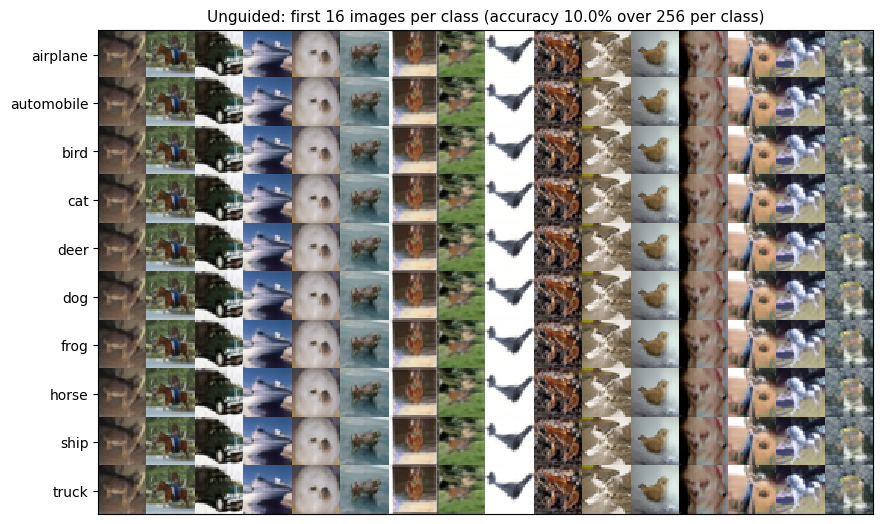

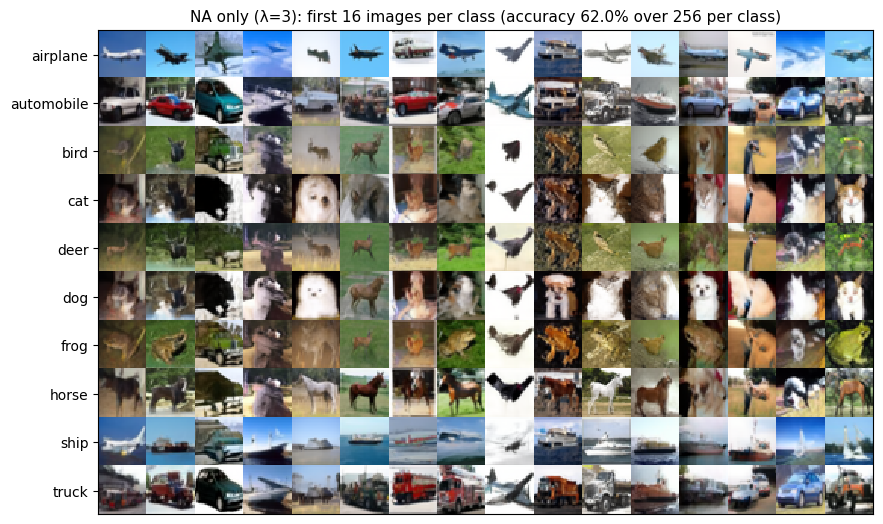

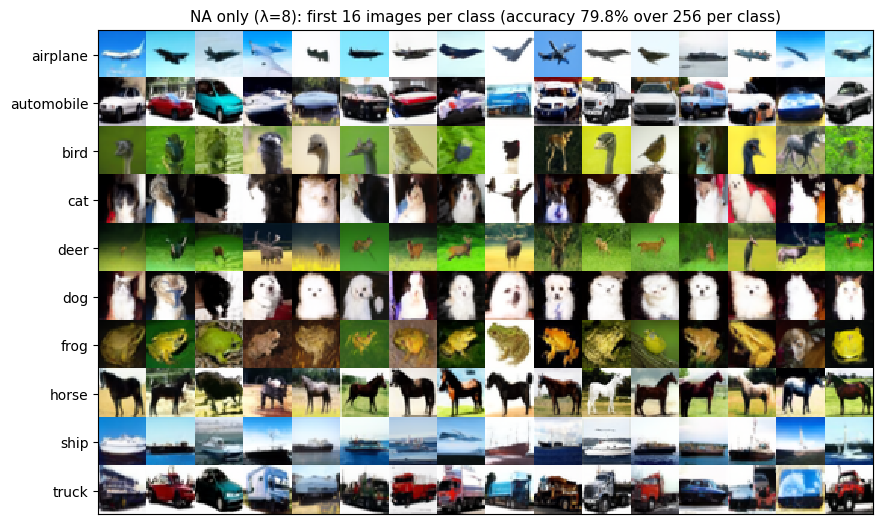

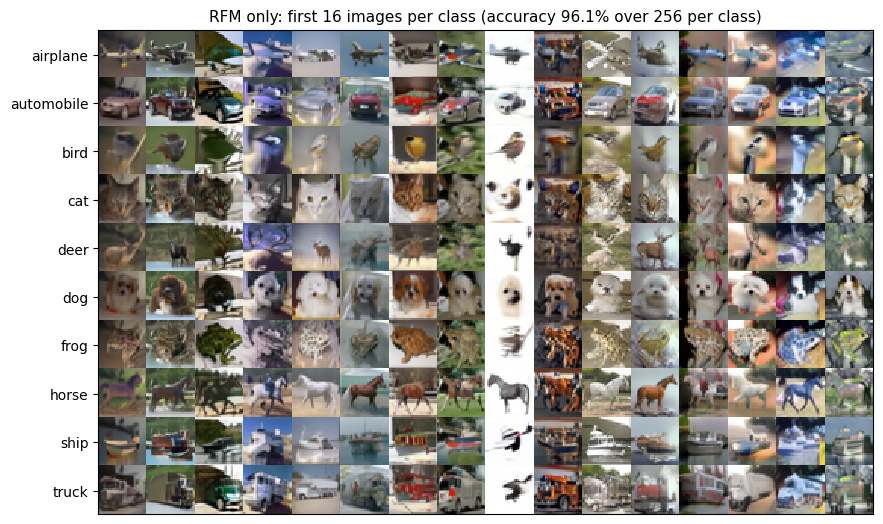

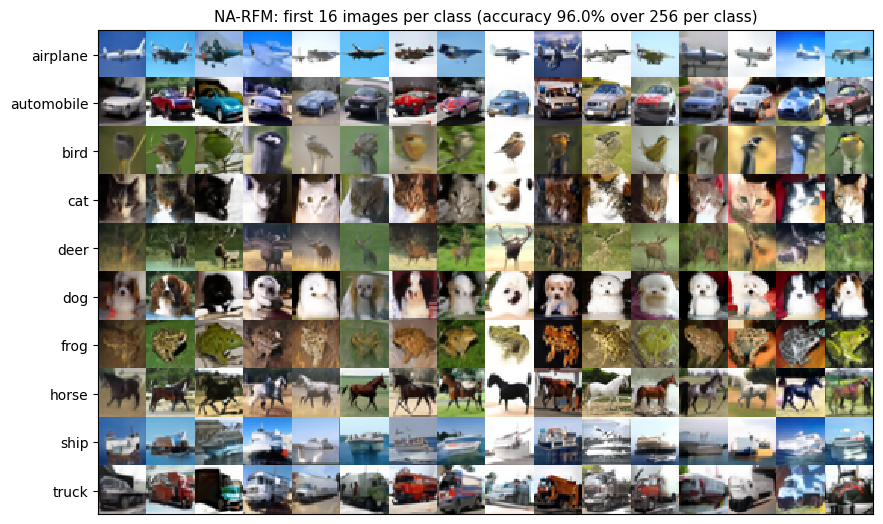

In [ ]:
def show_grid(label, n=16):
    """The first n images of every class for one row like the paper's Figures 9 and 10."""
    rows = []
    for name in CLASSES:
        x = torch.load(DIRS[label] / name / "samples.pt", map_location="cpu", weights_only=False)
        if isinstance(x, dict):
            x = x["samples"]
        x = (x[:n].clamp(-1, 1) + 1) / 2 # n x 3 x 32 x 32 in [0, 1]
        rows.append(torch.cat(list(x), dim=2)) # 3 x 32 x (32 n)
    img = torch.cat(rows, dim=1).permute(1, 2, 0).numpy() # (10 x 32) x (32 n) x 3
    fig, ax = plt.subplots(figsize=(10, 6.8))
    ax.imshow(img, interpolation="nearest")
    ax.set_yticks([16 + 32 * i for i in range(10)])
    ax.set_yticklabels(CLASSES)
    ax.set_xticks([])
    acc = QUALITY[label]["average_accuracy"] if label in QUALITY else float("nan")
    ax.set_title(f"{label}: first {n} images per class (accuracy {acc:.1f}% over 256 per class)", fontsize=11)
    safe = ROW_DIR[label]
    fig.savefig(SAVE / f"grid_{safe}.png", dpi=200, bbox_inches="tight")
    plt.show()


for label in ROW_DIR:
    if (DIRS[label] / "summary.json").exists():
        show_grid(label)

In [ ]:
expected = [f"rows/{r}/{c}/samples.pt" for r in ROW_DIR.values() for c in CLASSES]
expected += [f"rows/{r}/{f}" for r in ROW_DIR.values() for f in ("summary.json", "quality.json")]
expected += [f"cifar10_filters/class_{k}.pt" for k in range(10)] + ["cifar10_filters/full_dataset.pt"]
expected += [f"cifar10_concepts/class_{k}.pt" for k in range(10)]
expected += ["rfm_auc.csv", "times.json", "table2_replication.csv"] + [f"grid_{r}.png" for r in ROW_DIR.values()]
missing = [p for p in expected if not (SAVE / p).exists()]
print("all", len(expected), "expected files present" if not missing else f"MISSING {len(missing)}: {missing}")

all 89 expected files present


In [ ]:
drive.flush_and_unmount()